# Retail Sales Exploratory Data Analysis

This notebook inspects the supplied CSV, detects actual columns, cleans a working copy, analyzes sales, customers, products, categories, correlations, and exports charts plus a business report. Missing fields are documented rather than invented.

In [2]:
# Output alias used by the report export cell.
reports = (Path("..").resolve() / "outputs" / "reports")
reports.mkdir(parents=True, exist_ok=True)

In [3]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
base = Path("..").resolve()
data_path = base / "data" / "retail_sales.csv"
chart_dir = base / "outputs" / "charts"
report_dir = base / "outputs" / "reports"
chart_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path) if data_path.exists() else pd.DataFrame()
print("Loaded:", data_path if not df.empty else "No CSV found")

def normalize(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def find_column(options):
    exact = {normalize(column): column for column in df.columns}
    for option in options:
        if normalize(option) in exact:
            return exact[normalize(option)]
    for column in df.columns:
        if any(normalize(option) in normalize(column) for option in options):
            return column
    return None

columns = {
    "date": find_column(["order date", "sale date", "transaction date", "date"]),
    "sales": find_column(["sales", "revenue", "sale amount", "amount", "total"]),
    "quantity": find_column(["quantity", "qty", "units sold", "units"]),
    "profit": find_column(["profit", "net profit", "margin"]),
    "product": find_column(["product name", "product", "item"]),
    "category": find_column(["product category", "category", "sub-category"]),
    "age": find_column(["customer age", "age"]),
    "gender": find_column(["gender", "sex"]),
    "discount": find_column(["discount", "discount rate"]),
}
print("Shape:", df.shape)
display(df.head())
display(df.tail())
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))
display(pd.DataFrame({"role": columns.keys(), "detected": columns.values()}))

if df.empty:
    print("Add the original CSV at data/retail_sales.csv and rerun all cells.")
else:
    display(pd.DataFrame({"missing_count": df.isna().sum(), "missing_percent": (df.isna().mean() * 100).round(2)}))
    print("Duplicate rows:", int(df.duplicated().sum()))
    print("Categorical unique counts:", df.select_dtypes("object").nunique().to_dict())
    df = df.drop_duplicates().copy()
    if columns["date"]:
        df[columns["date"]] = pd.to_datetime(df[columns["date"]], errors="coerce")
    for role in ["sales", "quantity", "profit", "age", "discount"]:
        if columns[role]:
            df[columns[role]] = pd.to_numeric(df[columns[role]], errors="coerce")
    display(df.isna().sum().to_frame("missing_after_conversion"))
    numeric = df.select_dtypes("number")
    if not numeric.empty:
        display(pd.DataFrame({"mean": numeric.mean(), "median": numeric.median(), "mode": numeric.mode().iloc[0], "std": numeric.std(), "min": numeric.min(), "max": numeric.max(), "variance": numeric.var(), "p25": numeric.quantile(.25), "p50": numeric.quantile(.5), "p75": numeric.quantile(.75)}))
    if columns["date"] and columns["sales"]:
        working = df.dropna(subset=[columns["date"], columns["sales"]]).copy()
        working["quarter"] = working[columns["date"]].dt.to_period("Q").astype(str)
        monthly = working.set_index(columns["date"]).resample("MS")[columns["sales"]].sum()
        quarterly = working.groupby("quarter")[columns["sales"]].sum()
        display(monthly.to_frame("monthly_sales")); display(quarterly.to_frame("quarterly_sales"))
        for series, name, color in [(monthly, "monthly_sales", "#1f77b4"), (quarterly, "quarterly_sales", "#ff7f0e")]:
            series.plot(figsize=(10, 4), marker="o", color=color, title=name.replace("_", " ").title())
            plt.xlabel("Period"); plt.ylabel("Sales"); plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(chart_dir / f"{name}.png", dpi=300); plt.show()
            display(Markdown(f"**Observation:** Highest period is {series.idxmax()} and lowest is {series.idxmin()}."))
    if columns["age"]:
        labels = ["Under 18", "18-25", "26-35", "36-45", "46-55", "56+"]
        df["age_group"] = pd.cut(df[columns["age"]], [-np.inf, 17, 25, 35, 45, 55, np.inf], labels=labels)
        age_counts = df["age_group"].value_counts().reindex(labels, fill_value=0)
        age_counts.plot.bar(title="Customer Age Groups"); plt.xlabel("Age group"); plt.ylabel("Records"); plt.tight_layout(); plt.savefig(chart_dir / "age_groups.png", dpi=300); plt.show()
        display(Markdown(f"**Observation:** Most represented age group is {age_counts.idxmax()}."))
    else:
        print("Age unavailable: no recognizable age column.")
    if columns["gender"]:
        gender_counts = df[columns["gender"]].fillna("Missing").value_counts()
        gender_counts.plot.bar(title="Gender Distribution"); plt.xlabel("Gender"); plt.ylabel("Records"); plt.tight_layout(); plt.savefig(chart_dir / "gender.png", dpi=300); plt.show()
        display(Markdown(f"**Observation:** Most frequent recorded gender is {gender_counts.idxmax()}."))
    else:
        print("Gender unavailable: no recognizable gender column.")
    top = pd.Series(dtype=float)
    if columns["product"] and columns["quantity"]:
        top = df.groupby(columns["product"])[columns["quantity"]].sum().nlargest(10)
        top.sort_values().plot.barh(title="Top 10 Products by Quantity"); plt.xlabel("Quantity"); plt.tight_layout(); plt.savefig(chart_dir / "top_products.png", dpi=300); plt.show()
        display(Markdown(f"**Observation:** Leading product is {top.index[0]}."))
    cats = pd.Series(dtype=float)
    if columns["category"] and columns["sales"]:
        cats = df.groupby(columns["category"])[columns["sales"]].sum().sort_values(ascending=False)
        cats.plot.bar(title="Revenue by Category"); plt.xlabel("Category"); plt.ylabel("Sales"); plt.xticks(rotation=35); plt.tight_layout(); plt.savefig(chart_dir / "category_revenue.png", dpi=300); plt.show()
        display(Markdown(f"**Observation:** Highest category is {cats.index[0]}; lowest is {cats.index[-1]}."))
    correlation = df.select_dtypes("number").corr()
    if correlation.shape[1] >= 2:
        sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Pearson Correlation Matrix"); plt.tight_layout(); plt.savefig(chart_dir / "correlation.png", dpi=300); plt.show()
        display(Markdown("**Observation:** Correlation describes association, not causation."))
    if columns["sales"] and columns["profit"]:
        sns.scatterplot(data=df, x=columns["sales"], y=columns["profit"]); plt.title("Sales versus Profit"); plt.tight_layout(); plt.savefig(chart_dir / "sales_profit.png", dpi=300); plt.show()
        display(Markdown("**Observation:** This highlights profit relationships and loss-making records."))
    if columns["sales"]:
        sns.histplot(df[columns["sales"]].dropna(), bins=30, kde=True); plt.title("Sales Distribution"); plt.xlabel("Sales"); plt.tight_layout(); plt.savefig(chart_dir / "sales_distribution.png", dpi=300); plt.show()
        display(Markdown("**Observation:** This shows transaction scale and outliers."))

insights = ["No findings: source CSV was absent."] if df.empty else []
recommendations = ["Add data/retail_sales.csv and rerun the notebook."] if df.empty else ["Track KPIs monthly after changes to evaluate impact."]
if not df.empty:
    if "monthly" in locals() and not monthly.empty:
        insights.append(f"Best sales month: {monthly.idxmax():%B %Y}."); recommendations.append(f"Plan inventory around {monthly.idxmax():%B %Y}; investigate the weakest month.")
    if not cats.empty:
        insights.append(f"Highest category: {cats.index[0]}; lowest: {cats.index[-1]}."); recommendations.append(f"Protect {cats.index[0]} and review {cats.index[-1]} pricing and assortment.")
    if not top.empty:
        insights.append(f"Best-selling product: {top.index[0]}."); recommendations.append(f"Use reorder thresholds for {top.index[0]} to reduce stockouts.")
    recommendations += ["Review negative-profit transactions and discount or cost drivers.", "Use observed demographics for campaign tests while checking representativeness."]
report = ["Retail Sales EDA Business Insights", "==================================", "", "Findings:"] + ["- " + x for x in insights] + ["", "Actionable recommendations:"] + [f"{i}. {x}" for i, x in enumerate(recommendations, 1)] + ["", "Limitations:", "- Results depend on fields in the supplied CSV.", "- Correlation does not establish causation."]
report_text = "\n".join(report) + "\n"
(reports / "business_insights.txt").write_text(report_text, encoding="utf-8")
print(report_text)

Loaded: No CSV found
Shape: (0, 0)


""


""


,column,dtype


,role,detected
0,date,None
1,sales,None
2,quantity,None
3,profit,None
4,product,None
5,category,None
6,age,None
7,gender,None
8,discount,None


Add the original CSV at data/retail_sales.csv and rerun all cells.
Retail Sales EDA Business Insights

Findings:
- No findings: source CSV was absent.

Actionable recommendations:
1. Add data/retail_sales.csv and rerun the notebook.

Limitations:
- Results depend on fields in the supplied CSV.
- Correlation does not establish causation.



Loaded uploaded dataset: /Users/atifnawaz/Desktop/OIBSIP/OIBSIP-/Retail_Sales_EDA/Sample - Superstore.csv
Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2017-119914,5/4/2017,5/9/2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


,dtype
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


,missing_count,missing_percent
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Customer Name,0,0.0
Segment,0,0.0
Country,0,0.0
City,0,0.0


Duplicate rows: 0
Age and gender analysis unavailable: those columns are not in this dataset.


,mean,median,mode,std,min,max,variance,p25,p50,p75
Row ID,4997.500000,4997.5000,1.00,2885.163629,1.000,9994.000,8.324169e+06,2499.25000,4997.5000,7495.750
Postal Code,55190.379428,56430.5000,10035.00,32063.693350,1040.000,99301.000,1.028080e+09,23223.00000,56430.5000,90008.000
Sales,229.858001,54.4900,12.96,623.245101,0.444,22638.480,3.884345e+05,17.28000,54.4900,209.940
Quantity,3.789574,3.0000,3.00,2.225110,1.000,14.000,4.951113e+00,2.00000,3.0000,5.000
Discount,0.156203,0.2000,0.00,0.206452,0.000,0.800,4.262242e-02,0.00000,0.2000,0.200
Profit,28.656896,8.6665,0.00,234.260108,-6599.978,8399.976,5.487780e+04,1.72875,8.6665,29.364
Year,2015.722233,2016.0000,2017.00,1.123555,2014.000,2017.000,1.262376e+00,2015.00000,2016.0000,2017.000


,total_sales
Month,
2014-01,14236.8950
2014-02,4519.8920
2014-03,55691.0090
2014-04,28295.3450
2014-05,23648.2870
2014-06,34595.1276
2014-07,33946.3930
2014-08,27909.4685
2014-09,81777.3508


,total_sales
Quarter,
2014Q1,74447.7960
2014Q2,86538.7596
2014Q3,143633.2123
2014Q4,179627.7302
2015Q1,68851.7386
2015Q2,89124.1870
2015Q3,130259.5752
2015Q4,182297.0082
2016Q1,93237.1810


,monthly_profit
Month,
2014-01,2450.1907
2014-02,862.3084
2014-03,498.7299
2014-04,3488.8352
2014-05,2738.7096
2014-06,4976.5244
2014-07,-841.4826
2014-08,5318.1050
2014-09,8328.0994


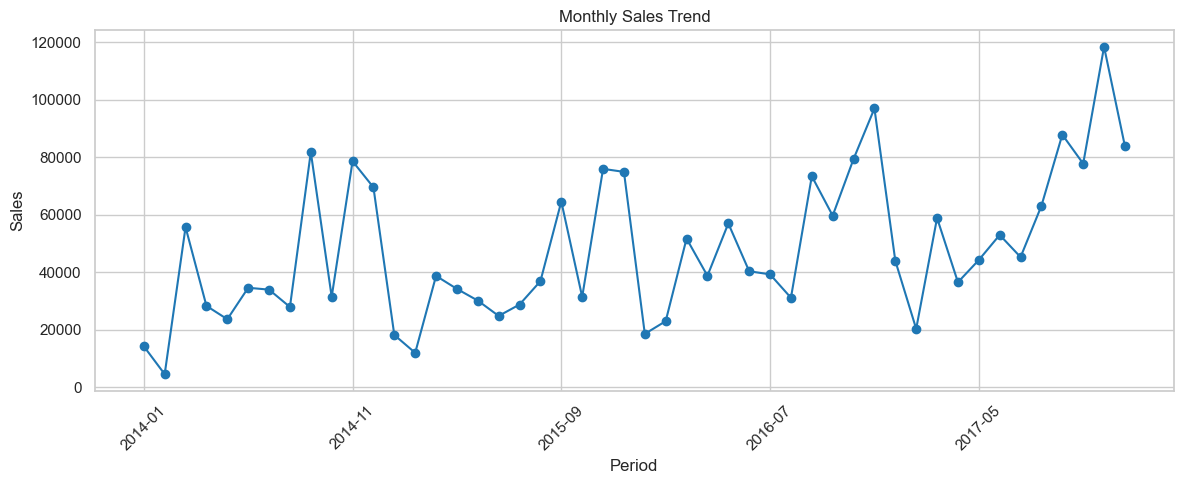

**Observation:** Highest period is 2017-11 (118,447.82); lowest is 2014-02 (4,519.89).

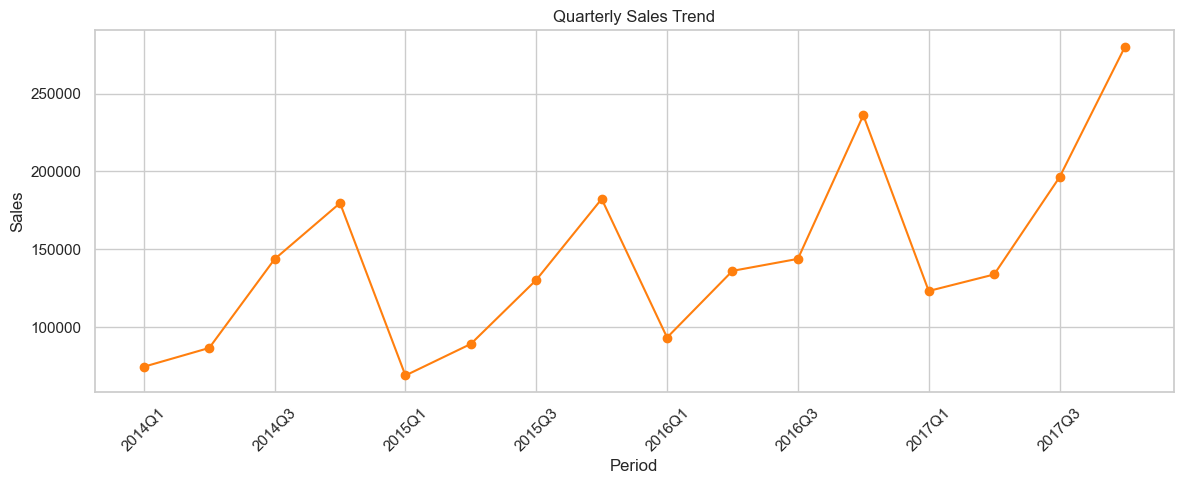

**Observation:** Highest period is 2017Q4 (280,054.07); lowest is 2015Q1 (68,851.74).

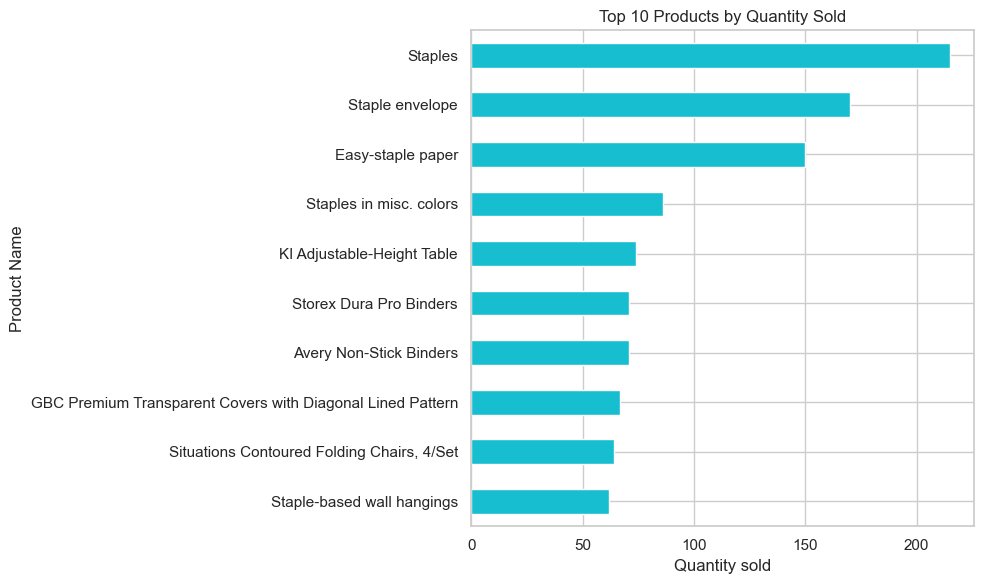

**Observation:** The best-selling product by quantity is Staples (215 units).

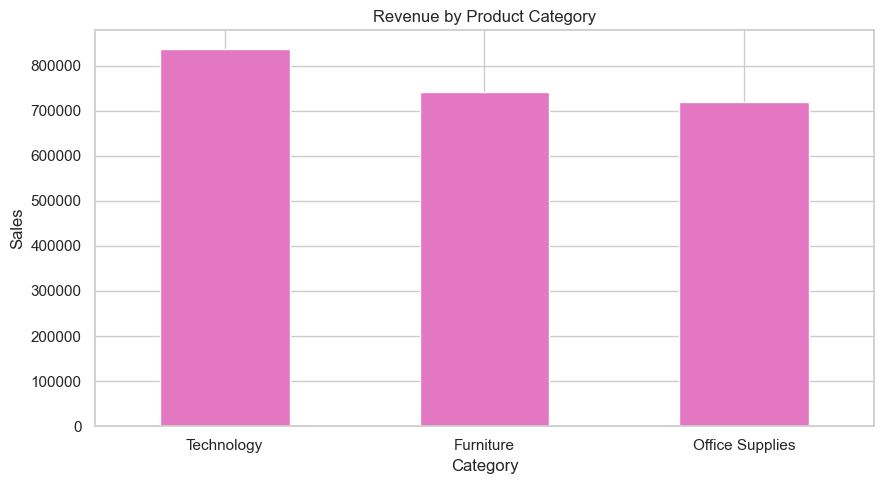

**Observation:** Highest-revenue category is Technology; lowest is Office Supplies.

,Sales,Profit,Quantity
Category,,,
Technology,836154.0330,145454.9481,6939
Office Supplies,719047.0320,122490.8008,22906
Furniture,741999.7953,18451.2728,8028


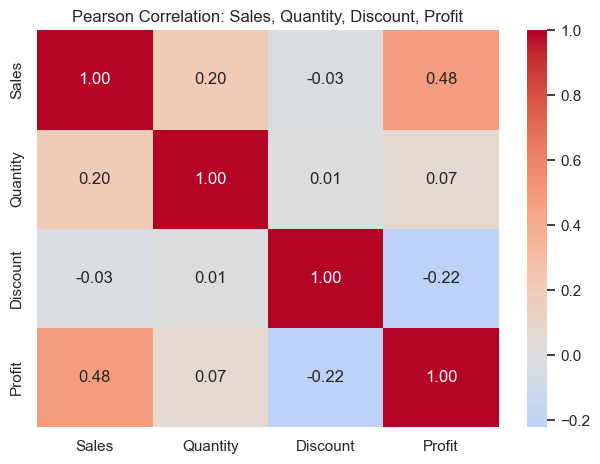

**Observation:** Correlation indicates linear association, not causation. Discount and profit should be reviewed together as a pricing risk indicator.

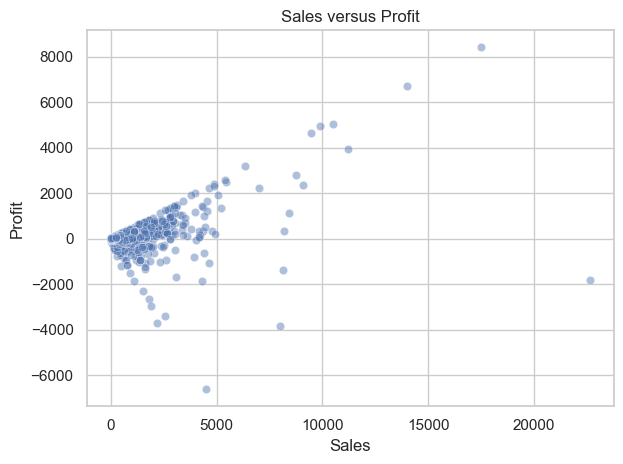

**Observation:** The scatter plot highlights high-value transactions and loss-making records.

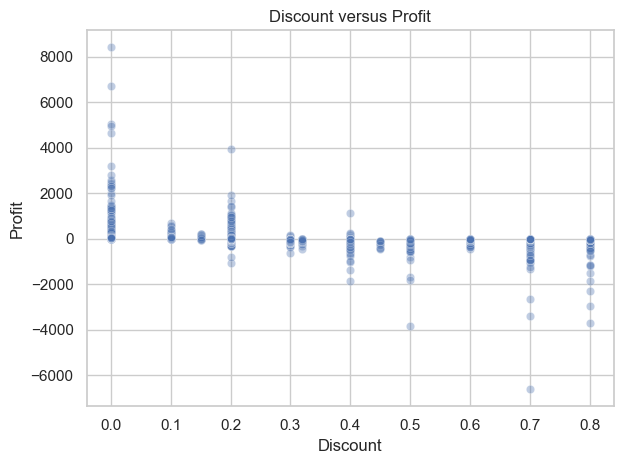

**Observation:** This visualization helps identify whether heavier discounts coincide with weaker profitability.

Retail Sales EDA Business Insights

Findings:
- Best sales month: 2017-11 (118,447.82).
- Most profitable category: Technology.
- Best-selling product by quantity: Staples.
- Lowest sales month: 2014-02 (4,519.89).

Actionable recommendations:
1. Prioritize inventory planning for the strongest sales period, 2017-11.
2. Protect availability of the leading category, Technology, while reviewing the lower-performing category, Office Supplies.
3. Use reorder thresholds for the top product, Staples.
4. Review high-discount transactions and loss-making products before expanding discount campaigns.
5. Use category-level profit, not sales alone, when evaluating assortment decisions.
6. Age and gender targeting cannot be evaluated because those fields are absent from the source dataset.

Limitations:
- Customer age and gender are not available in Sample - Superstore.csv.
- Correlation does not establish causation.


In [4]:
# Uploaded dataset: Sample - Superstore.csv
# This source uses latin1 encoding and does not contain customer age or gender.
source_path = base / "Sample - Superstore.csv"
df = pd.read_csv(source_path, encoding="latin1")
print("Loaded uploaded dataset:", source_path)
print("Shape:", df.shape)
display(df.head())
display(df.tail())
display(df.dtypes.to_frame("dtype"))
display(pd.DataFrame({"missing_count": df.isna().sum(), "missing_percent": (df.isna().mean() * 100).round(2)}))
print("Duplicate rows:", int(df.duplicated().sum()))

# Clean a working copy while preserving the uploaded source file.
df = df.drop_duplicates().copy()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")
for column in ["Sales", "Quantity", "Discount", "Profit"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Quarter"] = df["Order Date"].dt.to_period("Q").astype(str)
print("Age and gender analysis unavailable: those columns are not in this dataset.")

numeric = df.select_dtypes(include=np.number)
stats = pd.DataFrame({"mean": numeric.mean(), "median": numeric.median(), "mode": numeric.mode().iloc[0], "std": numeric.std(), "min": numeric.min(), "max": numeric.max(), "variance": numeric.var(), "p25": numeric.quantile(.25), "p50": numeric.quantile(.50), "p75": numeric.quantile(.75)})
display(stats)
monthly = df.groupby("Month")["Sales"].sum()
quarterly = df.groupby("Quarter")["Sales"].sum()
monthly_profit = df.groupby("Month")["Profit"].sum()
display(monthly.to_frame("total_sales")); display(quarterly.to_frame("total_sales")); display(monthly_profit.to_frame("monthly_profit"))

for series, title, filename, color in [(monthly, "Monthly Sales Trend", "monthly_sales_uploaded.png", "#1f77b4"), (quarterly, "Quarterly Sales Trend", "quarterly_sales_uploaded.png", "#ff7f0e")]:
    series.plot(figsize=(12, 5), marker="o", color=color, title=title)
    plt.xlabel("Period"); plt.ylabel("Sales"); plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(chart_dir / filename, dpi=300); plt.show()
    display(Markdown(f"**Observation:** Highest period is {series.idxmax()} ({series.max():,.2f}); lowest is {series.idxmin()} ({series.min():,.2f})."))

top_products = df.groupby("Product Name")["Quantity"].sum().nlargest(10)
top_products.sort_values().plot.barh(figsize=(10, 6), color="#17becf", title="Top 10 Products by Quantity Sold")
plt.xlabel("Quantity sold"); plt.tight_layout(); plt.savefig(chart_dir / "top_products_uploaded.png", dpi=300); plt.show()
display(Markdown(f"**Observation:** The best-selling product by quantity is {top_products.index[0]} ({top_products.iloc[0]:,.0f} units)."))

category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category_sales.plot.bar(figsize=(9, 5), color="#e377c2", title="Revenue by Product Category")
plt.xlabel("Category"); plt.ylabel("Sales"); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(chart_dir / "category_revenue_uploaded.png", dpi=300); plt.show()
display(Markdown(f"**Observation:** Highest-revenue category is {category_sales.index[0]}; lowest is {category_sales.index[-1]}."))
display(df.groupby("Category")[["Sales", "Profit", "Quantity"]].sum().sort_values("Profit", ascending=False))

correlation = df[["Sales", "Quantity", "Discount", "Profit"]].corr()
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson Correlation: Sales, Quantity, Discount, Profit"); plt.tight_layout(); plt.savefig(chart_dir / "correlation_uploaded.png", dpi=300); plt.show()
display(Markdown("**Observation:** Correlation indicates linear association, not causation. Discount and profit should be reviewed together as a pricing risk indicator."))

sns.scatterplot(data=df, x="Sales", y="Profit", alpha=0.45)
plt.title("Sales versus Profit"); plt.tight_layout(); plt.savefig(chart_dir / "sales_profit_uploaded.png", dpi=300); plt.show()
display(Markdown("**Observation:** The scatter plot highlights high-value transactions and loss-making records."))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35)
plt.title("Discount versus Profit"); plt.tight_layout(); plt.savefig(chart_dir / "discount_profit_uploaded.png", dpi=300); plt.show()
display(Markdown("**Observation:** This visualization helps identify whether heavier discounts coincide with weaker profitability."))

recommendations = [
    f"Prioritize inventory planning for the strongest sales period, {monthly.idxmax()}.",
    f"Protect availability of the leading category, {category_sales.index[0]}, while reviewing the lower-performing category, {category_sales.index[-1]}.",
    f"Use reorder thresholds for the top product, {top_products.index[0]}.",
    "Review high-discount transactions and loss-making products before expanding discount campaigns.",
    "Use category-level profit, not sales alone, when evaluating assortment decisions.",
    "Age and gender targeting cannot be evaluated because those fields are absent from the source dataset."
]
insights = [f"Best sales month: {monthly.idxmax()} ({monthly.max():,.2f}).", f"Most profitable category: {df.groupby('Category')['Profit'].sum().idxmax()}.", f"Best-selling product by quantity: {top_products.index[0]}.", f"Lowest sales month: {monthly.idxmin()} ({monthly.min():,.2f})."]
report_lines = ["Retail Sales EDA Business Insights", "==================================", "", "Findings:"] + ["- " + item for item in insights] + ["", "Actionable recommendations:"] + [f"{i}. {item}" for i, item in enumerate(recommendations, 1)] + ["", "Limitations:", "- Customer age and gender are not available in Sample - Superstore.csv.", "- Correlation does not establish causation."]
(report_dir / "business_insights.txt").write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("\n".join(report_lines))